**Introducción a la Ciencia de Datos 2026**
Posgrado en Ciencias de la Computación - CICESE
Dr. Irvin Hussein López Nava

## ICD - 15: Aprendizaje basado en instancias

Sesión 15 del curso. Diapositivas: [icd-15-aprendizaje-instancias.pdf](https://github.com/husseinlopez/icd2026/blob/main/clases/icd-15-aprendizaje-instancias.pdf)

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/husseinlopez/icd2026/blob/main/icd-15-aprendizaje-instancias.ipynb)

Las sesiones 13 y 14 abrieron dos cajas negras de la sesión 12: el árbol de decisión y Naive Bayes. Hoy abrimos la tercera: **el vecino más cercano**. No construye un modelo; guarda los ejemplos y, ante una consulta, busca los más parecidos y los deja votar.

El notebook tiene cinco partes. En la primera calculamos vecinos a mano: la distancia de Hamming con *Play tennis* y el caso de los 14 días de prueba. En la segunda pasamos los mismos días a scikit-learn, elegimos *k* sin mirar la prueba y comparamos con el árbol y Naive Bayes. En la tercera volvemos al vino de la sesión 12 con el protocolo del notebook 13: la escala, los duplicados y los pesos por distancia. En la cuarta medimos la maldición de la dimensionalidad, y en la quinta usamos vecinos para regresión.

---

### Preparación

Las bibliotecas de siempre, más `statsmodels` para la regresión local de la sección 5.

In [1]:
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import sklearn
import statsmodels

print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)
print("statsmodels ", statsmodels.__version__)

numpy        2.5.3
pandas       3.0.5
scikit-learn 1.9.1
statsmodels  0.15.0


Paleta y estilo de las sesiones anteriores. El naranja sigue siendo lo que produce el modelo.

In [2]:
AZUL_OSCURO = "#112057"
AZUL = "#7697CD"
AZUL_MEDIO = "#3C51A9"
NARANJA = "#E76A28"      # lo que produce el modelo
GRIS = "#5B6584"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.titlecolor": AZUL_OSCURO,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.labelcolor": AZUL_OSCURO,
    "axes.edgecolor": "#C9CFDF",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#E3E6EF",
    "xtick.color": GRIS,
    "ytick.color": GRIS,
    "legend.frameon": False,
})
warnings.filterwarnings("ignore", category=FutureWarning)

SEMILLA = 42                        # fija las particiones para que los resultados se repitan
CLASES = ["baja", "media", "alta"]  # el orden en que se muestran las clases del vino
COLOR_CLASE = {"baja": NARANJA, "media": AZUL, "alta": AZUL_OSCURO}

---

### Los datos

- `weather.nominal.csv` y `weather.numeric.csv` son los 14 días de *Play tennis* de las sesiones 13 y 14.
- `weather.prueba.csv` tiene 14 días nuevos, con el mismo formato que `weather.numeric.csv`: son los días de prueba del caso de estudio (lámina 25).
- `vinos-3clases.csv` es el vino de 3 clases de la sesión 12.

En las cuatro lecturas, la primera línea funciona tal cual desde la carpeta del repositorio clonado. En Colab, comenta la primera y descomenta la segunda.

In [3]:
nominal = pd.read_csv("datos/weather.nominal.csv")
# nominal = pd.read_csv("https://raw.githubusercontent.com/husseinlopez/icd2026/main/datos/weather.nominal.csv")

entrena = pd.read_csv("datos/weather.numeric.csv")
# entrena = pd.read_csv("https://raw.githubusercontent.com/husseinlopez/icd2026/main/datos/weather.numeric.csv")

prueba = pd.read_csv("datos/weather.prueba.csv")
# prueba = pd.read_csv("https://raw.githubusercontent.com/husseinlopez/icd2026/main/datos/weather.prueba.csv")

vinos = pd.read_csv("datos/vinos-3clases.csv")
# vinos = pd.read_csv("https://raw.githubusercontent.com/husseinlopez/icd2026/main/datos/vinos-3clases.csv")

print("Prueba:", len(prueba), "días;", prueba.Play.sum(), "Sí y", (~prueba.Play).sum(), "No")
prueba

Prueba: 14 días; 9 Sí y 5 No


,Day,Outlook,Temperature,Humidity,Wind,Play
0,15,sunny,81,88,strong,False
1,16,overcast,74,92,weak,True
2,17,rain,76,85,weak,True
3,18,sunny,78,75,strong,False
4,19,sunny,82,92,weak,False
5,20,rain,67,90,strong,False
6,21,overcast,85,85,strong,True
7,22,rain,73,88,weak,True
8,23,sunny,88,65,strong,True
9,24,overcast,77,70,weak,True


**Lectura.** La prueba tiene 9 Sí y 5 No, la misma proporción que el entrenamiento. `Play` vale `True` para Sí. `Day` es un identificador y no entra al modelo (sesión 13).

---

## 1. Vecinos a mano

### La distancia de Hamming con *Play tennis*

Volvemos a la instancia de las sesiones 13 y 14: {sunny, cool, high, strong}. Con atributos nominales no hay restas; la **distancia de Hamming** cuenta cuántos atributos no coinciden (lámina 20).

In [4]:
ATRIBUTOS = ["Outlook", "Temperature", "Humidity", "Wind"]
consulta = pd.Series({"Outlook": "sunny", "Temperature": "cool", "Humidity": "high", "Wind": "strong"})

hamming = (nominal[ATRIBUTOS] != consulta).sum(axis=1)
tabla = nominal.assign(d=hamming).sort_values(["d", "Day"], kind="stable")
pd.crosstab(tabla.d, tabla.Play.map({True: "Sí", False: "No"}))

Play,No,Sí
d,,
1,1,0
2,4,4
3,0,3
4,0,2


**Lectura.** El día 2 es el único a distancia 1, y dice No. A distancia 2 hay ocho días: cuatro No y cuatro Sí.

- Con $k = 1$ la respuesta es No.
- Con $k = 3$ entran el día 2 y **dos** de esos ocho, y no hay forma de saber cuáles: es un empate en la distancia.
- Con $k = 9$ entran todos los días a distancia 2 o menos, y gana No, 5 contra 4.

Con pesos, los empates pesan igual y desaparece el problema. El método de Shepard deja votar a los 14 días (lámina 34):

In [5]:
for potencia in [2, 1]:
    pesos = 1 / hamming ** potencia
    suma = pesos.groupby(nominal.Play.map({True: "Sí", False: "No"})).sum()
    print(f"w = 1/d^{potencia}:  No {suma['No']:.4f}   Sí {suma['Sí']:.4f}   P(No) = {suma['No'] / suma.sum():.3f}")

w = 1/d^2:  No 2.0000   Sí 1.4583   P(No) = 0.578
w = 1/d^1:  No 3.0000   Sí 3.5000   P(No) = 0.462


**Lectura.** Con $w = 1/d^2$, como en Mitchell, gana No (0.578). Con $w = 1/d$, que es lo que usa scikit-learn con `weights="distance"`, gana Sí. La potencia del peso decide.

### kNN en NumPy

El algoritmo de la lámina 19 cabe en una función. `np.argsort` ordena las distancias; el libro (capítulo 11, *Sorting Arrays*) muestra que `np.argpartition` basta cuando solo importan los $k$ primeros.

In [6]:
def knn_predice(X_entrena, y_entrena, X_consulta, k):
    # Distancia euclidiana de cada consulta a cada ejemplo: una matriz de consultas × ejemplos.
    d = np.sqrt(((X_consulta[:, None, :] - X_entrena[None, :, :]) ** 2).sum(axis=2))
    vecinos = np.argsort(d, axis=1, kind="stable")[:, :k]       # los k más cercanos de cada consulta
    predicciones = []
    for fila in y_entrena[vecinos]:
        clases, votos = np.unique(fila, return_counts=True)       # np.unique ordena las clases
        predicciones.append(clases[np.argmax(votos)])             # en un empate gana la primera
    return np.array(predicciones), d

### El caso de estudio: 14 días de entrenamiento y 14 de prueba

Ahora con `weather.numeric`: la temperatura y la humedad son números. Antes de medir distancias hay que **codificar** y **escalar** (lámina 26):

- `Outlook` pasa a *one-hot*: tres columnas 0/1. Con códigos 0, 1 y 2, sunny quedaría a 2 de rain y a 1 de overcast, un orden que no existe.
- `Wind` pasa a 0/1.
- La temperatura y la humedad pasan a $z = (x - \mu)/\sigma$, con $\mu$ y $\sigma$ **del entrenamiento**. La prueba se escala con esos mismos valores.

In [7]:
CIELO = ["sunny", "overcast", "rain"]
mu = entrena[["Temperature", "Humidity"]].mean()
sigma = entrena[["Temperature", "Humidity"]].std(ddof=0)        # con n, como StandardScaler


def codifica(df, escalar=True):
    X = pd.DataFrame({c: (df.Outlook == c).astype(float) for c in CIELO})
    numericas = df[["Temperature", "Humidity"]].astype(float)
    if escalar:
        numericas = (numericas - mu) / sigma                      # μ y σ del entrenamiento, también para la prueba
    X["z temp" if escalar else "temp"] = numericas.Temperature
    X["z hum" if escalar else "hum"] = numericas.Humidity
    X["wind"] = (df.Wind == "strong").astype(float)
    return X


print("μ:", mu.round(2).to_dict(), "  σ:", sigma.round(2).to_dict())
pd.concat([codifica(entrena).head(2), codifica(prueba).head(2)], keys=["entrenamiento", "prueba"]).round(2)

μ: {'Temperature': 73.57, 'Humidity': 81.64}   σ: {'Temperature': 6.33, 'Humidity': 9.91}


sunny  overcast  rain  z temp  z hum  wind
entrenamiento 0    1.0       0.0   0.0    1.80   0.34   0.0
              1    1.0       0.0   0.0    1.02   0.84   1.0
prueba        0    1.0       0.0   0.0    1.17   0.64   1.0
              1    0.0       1.0   0.0    0.07   1.05   0.0

**Lectura.** El día 1 (sunny, 85, 85, weak) queda como (1, 0, 0, 1.80, 0.34, 0), y el día 15 de prueba (sunny, 81, 88, strong) como (1, 0, 0, 1.17, 0.64, 1).

### Los vecinos del día 15

In [8]:
X_entrena, X_prueba = codifica(entrena).to_numpy(), codifica(prueba).to_numpy()
y_entrena, y_prueba = entrena.Play.to_numpy(), prueba.Play.to_numpy()

_, distancias = knn_predice(X_entrena, y_entrena, X_prueba[:1], k=1)
orden = np.argsort(distancias[0], kind="stable")
vecinos_15 = pd.DataFrame({"día": entrena.Day.to_numpy()[orden], "d": distancias[0][orden].round(2),
                           "Play": np.where(y_entrena[orden], "Sí", "No")})
for k in [1, 3, 5, 7]:
    votos = vecinos_15.Play.head(k).value_counts()
    print(f"k = {k}: No {votos.get('No', 0)}, Sí {votos.get('Sí', 0)} → {'Sí' if votos.get('Sí', 0) > votos.get('No', 0) else 'No'}")
vecinos_15.head(8)

k = 1: No 1, Sí 0 → No
k = 3: No 2, Sí 1 → No
k = 5: No 3, Sí 2 → No
k = 7: No 3, Sí 4 → Sí


,día,d,Play
0,2,0.26,No
1,1,1.22,No
2,3,1.77,Sí
3,8,1.88,No
4,12,2.02,Sí
5,11,2.05,Sí
6,10,2.13,Sí
7,14,2.14,No


**Lectura.** El día 2 está a 0.26: solo cambian un poco la temperatura y la humedad. Con $k = 5$ gana No, 3 a 2; con $k = 7$ entran dos Sí más y la predicción cambia. La clase real del día 15 es No.

### Los 14 días de prueba, con y sin escalar

In [9]:
X_entrena_crudo, X_prueba_crudo = codifica(entrena, False).to_numpy(), codifica(prueba, False).to_numpy()
aciertos = {}
for nombre, (A, B) in {"con z-scores": (X_entrena, X_prueba), "sin escalar": (X_entrena_crudo, X_prueba_crudo)}.items():
    aciertos[nombre] = {f"k = {k}": int((knn_predice(A, y_entrena, B, k)[0] == y_prueba).sum()) for k in [1, 3, 5, 7]}
pd.DataFrame(aciertos).T

,k = 1,k = 3,k = 5,k = 7
con z-scores,13,11,10,8
sin escalar,11,7,7,10


**Lectura.** Con z-scores, 13, 11, 10 y 8 aciertos de 14. Con $k = 7$, 13 de los 14 días salen Sí: la clase mayoritaria se impone. Sin escalar, 11, 7, 7 y 10.

¿Por qué cambia tanto? Veamos el día 21 (overcast, 85, 85, strong; Sí):

In [10]:
for nombre, (A, B) in {"sin escalar": (X_entrena_crudo, X_prueba_crudo), "con z-scores": (X_entrena, X_prueba)}.items():
    d = np.sqrt(((A - B[6]) ** 2).sum(axis=1))
    i = int(np.argmin(d))
    r = entrena.iloc[i]
    print(f"{nombre:13s}: más cercano, el día {r.Day} ({r.Outlook}, {r.Temperature}, {r.Humidity}, {r.Wind}), a {d[i]:.2f} → {'Sí' if r.Play else 'No'}")

sin escalar  : más cercano, el día 1 (sunny, 85, 85, weak), a 1.73 → No
con z-scores : más cercano, el día 3 (overcast, 83, 86, weak), a 1.05 → Sí


**Lectura.** Sin escalar, el día 1 coincide en temperatura y humedad, y queda a $\sqrt{2 + 1} = 1.73$ aunque cambian el cielo y el viento. El día 3, que comparte el cielo y dice Sí, queda a $\sqrt{2^2 + 1^2 + 1} = 2.45$: dos grados y un punto de humedad pesan más que el cielo. Con z-scores, el día 3 pasa a ser el más cercano, a 1.05.

---

## 2. Los mismos días en scikit-learn

`KNeighborsClassifier` hace lo mismo que nuestra función. La codificación y el escalado van en un `ColumnTransformer` dentro de un `Pipeline`, para que cada partición aprenda $\mu$ y $\sigma$ solo de su entrenamiento (sesión 12).

In [11]:
from sklearn.compose import make_column_transformer
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

COLUMNAS = ["Outlook", "Temperature", "Humidity", "Wind"]


def knn_weather(k):
    prepara = make_column_transformer(
        (OneHotEncoder(categories=[CIELO]), ["Outlook"]),
        (StandardScaler(), ["Temperature", "Humidity"]),
        (OneHotEncoder(categories=[["weak", "strong"]], drop="first"), ["Wind"]))
    return make_pipeline(prepara, KNeighborsClassifier(n_neighbors=k))


for k in [1, 3, 5, 7]:
    modelo = knn_weather(k).fit(entrena[COLUMNAS], entrena.Play)
    print(f"k = {k}: {int((modelo.predict(prueba[COLUMNAS]) == prueba.Play).sum())}/14")

k = 1: 13/14
k = 3: 11/14
k = 5: 10/14


k = 7: 8/14


**Lectura.** Las mismas cifras que a mano.

### Elegir *k* sin mirar la prueba

Si elegimos $k$ con la prueba, gana $k = 1$ con 13/14, pero ese 93 % es optimista: la prueba ya influyó en la decisión (notebook 13). Lo correcto es elegir $k$ con validación cruzada dentro del entrenamiento. Con 14 días usamos *dejar uno fuera*: cada día se clasifica con los otros 13.

In [12]:
loo = {}
for k in [1, 3, 5, 7]:
    pred = cross_val_predict(knn_weather(k), entrena[COLUMNAS], entrena.Play, cv=LeaveOneOut())
    loo[k] = int((pred == entrena.Play).sum())
k_elegido = min(k for k in loo if loo[k] == max(loo.values()))     # en un empate, el menor
modelo = knn_weather(k_elegido).fit(entrena[COLUMNAS], entrena.Play)
print("Dejando uno fuera:", loo, "→ k =", k_elegido)
print(f"Prueba, una sola vez: {int((modelo.predict(prueba[COLUMNAS]) == prueba.Play).sum())}/14")

Dejando uno fuera: {1: 8, 3: 7, 5: 9, 7: 9} → k = 5
Prueba, una sola vez: 10/14


**Lectura.** Empatan $k = 5$ y $k = 7$ con 9 de 14; con el menor, la prueba da 10/14 (71 %). Con 14 días, un acierto vale 7 puntos: toda estimación es incierta.

### La unidad en los mismos 14 días

El árbol J48 de la sesión 13 pregunta por `Outlook`; luego, en sunny, por la humedad (≤ 75 es Sí) y en rain por el viento. Naive Bayes, como en la sesión 14: frecuencias para `Outlook` y `Wind`, y una normal por clase para la temperatura y la humedad.

In [13]:
from scipy.stats import norm

arbol = np.where(prueba.Outlook == "overcast", True,
                 np.where(prueba.Outlook == "sunny", prueba.Humidity <= 75, prueba.Wind == "weak"))


def naive_bayes(fila):
    puntaje = {}
    for clase in [True, False]:
        sub = entrena[entrena.Play == clase]
        p = len(sub) / len(entrena) * (sub.Outlook == fila.Outlook).mean() * (sub.Wind == fila.Wind).mean()
        for a in ["Temperature", "Humidity"]:
            p *= norm.pdf(fila[a], sub[a].mean(), sub[a].std(ddof=1))
        puntaje[clase] = p
    return max(puntaje, key=puntaje.get)


bayes = prueba.apply(naive_bayes, axis=1)
unidad = pd.DataFrame({"aciertos": [int((arbol == prueba.Play).sum()), int((bayes == prueba.Play).sum()),
                                    int((modelo.predict(prueba[COLUMNAS]) == prueba.Play).sum()), aciertos["con z-scores"]["k = 1"]]},
                      index=["árbol J48 (sesión 13)", "Naive Bayes (sesión 14)", f"kNN, k = {k_elegido} (dejando uno fuera)", "kNN, k = 1 (elegido con la prueba)"])
unidad["exactitud"] = (unidad.aciertos / 14).round(2)
unidad

,aciertos,exactitud
árbol J48 (sesión 13),12,0.86
Naive Bayes (sesión 14),12,0.86
"kNN, k = 5 (dejando uno fuera)",10,0.71
"kNN, k = 1 (elegido con la prueba)",13,0.93


**Lectura.** El árbol y Naive Bayes aciertan 12; el kNN, 10 u 13 según cómo se elija $k$. Un día vale 7 puntos, así que ninguna diferencia es concluyente. Por eso la comparación seria se hace en la sección 3, con 1599 vinos. En la sesión 16, el SVM se prueba con estos mismos días.

### Tres detalles de scikit-learn

**1. Códigos como números.** Con `OrdinalEncoder` y la distancia euclidiana, los códigos se restan como si tuvieran orden. Comparamos con Hamming en las 36 combinaciones posibles de *Play tennis*:

In [14]:
from itertools import product

codigos = OrdinalEncoder().fit(nominal[ATRIBUTOS])
X_cod = codigos.transform(nominal[ATRIBUTOS])
y_nom = nominal.Play.map({True: "Sí", False: "No"})
todas = pd.DataFrame(list(product(*codigos.categories_)), columns=ATRIBUTOS)
X_todas = codigos.transform(todas)
for k in [1, 3, 5]:
    ham = KNeighborsClassifier(n_neighbors=k, metric="hamming").fit(X_cod, y_nom).predict(X_todas)
    euc = KNeighborsClassifier(n_neighbors=k).fit(X_cod, y_nom).predict(X_todas)
    print(f"k = {k}: {int((ham != euc).sum())} de 36 combinaciones cambian de clase")

k = 1: 2 de 36 combinaciones cambian de clase
k = 3: 3 de 36 combinaciones cambian de clase
k = 5: 3 de 36 combinaciones cambian de clase


**Lectura.** Cambian 2 de 36 con $k = 1$ y 3 con $k = 3$ y $k = 5$. Con *one-hot*, en cambio, la distancia euclidiana es $\sqrt{2 \times \text{Hamming}}$ y encuentra los mismos vecinos.

**2. Empates en la distancia.** El caso de $k = 3$ en la consulta {sunny, cool, high, strong}: ¿qué dos días de los ocho a distancia 2 entran? Lo decide el orden de los datos (la documentación de `KNeighborsClassifier` lo advierte).

In [15]:
x_cod = codigos.transform(consulta.to_frame().T)
rng = np.random.default_rng(0)
respuestas = []
for _ in range(200):
    perm = rng.permutation(len(X_cod))
    respuestas.append(KNeighborsClassifier(n_neighbors=3, metric="hamming").fit(X_cod[perm], y_nom.iloc[perm]).predict(x_cod)[0])
print("200 órdenes al azar de los mismos 14 días:", pd.Series(respuestas).value_counts().to_dict())
for algoritmo in ["brute", "ball_tree"]:
    m = KNeighborsClassifier(n_neighbors=3, metric="hamming", algorithm=algoritmo).fit(X_cod, y_nom)
    print(f"{algoritmo:9s}: vecinos = días {list(nominal.Day[m.kneighbors(x_cod)[1][0]])}, predice {m.predict(x_cod)[0]}")

200 órdenes al azar de los mismos 14 días: {'No': 147, 'Sí': 53}
brute    : vecinos = días [2, 1, 7], predice No
ball_tree: vecinos = días [2, 6, 1], predice No


**Lectura.** Con los mismos datos, 53 de 200 órdenes dan Sí. Incluso el algoritmo de búsqueda elige distintos días empatados.

**3. Los pesos.** `weights="distance"` usa $1/d$, no el $1/d^2$ de Mitchell (lámina 34):

In [16]:
pesado = KNeighborsClassifier(n_neighbors=14, metric="hamming", weights="distance").fit(X_cod, y_nom)
print("weights='distance', los 14 días:", {c: round(float(p), 3) for c, p in zip(pesado.classes_, pesado.predict_proba(x_cod)[0])})

weights='distance', los 14 días: {'No': 0.462, 'Sí': 0.538}


**Lectura.** Sí con 0.538, como el cálculo a mano con $w = 1/d$ de la sección 1.

---

## 3. El vino con el protocolo del notebook 13

Volvemos al vino de 3 clases: 20 % para prueba con los duplicados del mismo lado, validación cruzada agrupada dentro del entrenamiento y la prueba una sola vez.

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, log_loss
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold, StratifiedKFold, cross_val_score, cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import MinMaxScaler
from sklearn.tree import DecisionTreeClassifier

X = vinos.drop(columns="calidad")
y = vinos["calidad"]
grupos = pd.util.hash_pandas_object(vinos, index=False)      # filas idénticas, mismo grupo (notebook 12)

i_entrena, i_prueba = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA).split(X, y, grupos))
X_e, X_p = X.iloc[i_entrena], X.iloc[i_prueba]
y_e, y_p = y.iloc[i_entrena], y.iloc[i_prueba]
g_e = grupos.iloc[i_entrena]
pliegues = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
print(f"Entrenamiento: {len(i_entrena)} vinos; prueba: {len(i_prueba)}")

Entrenamiento: 1279 vinos; prueba: 320


### La escala decide quiénes son los vecinos

La distancia al cuadrado entre dos vinos al azar es, en promedio, $2\sum_r \mathrm{var}(a_r)$: cada atributo aporta su varianza.

In [18]:
varianza = X_e.var()
(100 * varianza / varianza.sum()).sort_values(ascending=False).round(2).head(4)

total sulfur dioxide    90.27
free sulfur dioxide      9.17
fixed acidity            0.26
residual sugar           0.18
dtype: float64

In [19]:
def vecinos(A, B, k=10):
    return NearestNeighbors(n_neighbors=k).fit(A).kneighbors(B, return_distance=False)


def comunes(a, b):
    return np.mean([len(set(r) & set(s)) / len(r) for r, s in zip(a, b)])


SO2 = ["total sulfur dioxide", "free sulfur dioxide"]
escalador = StandardScaler().fit(X_e)
crudos = vecinos(X_e, X_p)
print(f"Vecinos en común con los de las dos columnas de SO₂: {comunes(crudos, vecinos(X_e[SO2], X_p[SO2])):.0%}")
print(f"Vecinos en común con los de los datos estandarizados: {comunes(crudos, vecinos(escalador.transform(X_e), escalador.transform(X_p))):.0%}")

Vecinos en común con los de las dos columnas de SO₂: 64%
Vecinos en común con los de los datos estandarizados: 11%


**Lectura.** Sin escalar, el SO₂ total aporta 90 % de la distancia, y con el SO₂ libre, 99 %. El vecino se elige casi solo por el SO₂: los 10 vecinos de cada vino de prueba coinciden en 64 % con los de las dos columnas de SO₂ solas, y apenas en 11 % con los de los datos estandarizados.

¿Cuánto cuesta? F1 macro con validación agrupada, con tres escaladores:

In [20]:
def evaluar(modelo, X_e_=X_e, X_p_=X_p):
    r = cross_validate(modelo, X_e_, y_e, groups=g_e, cv=pliegues, scoring="f1_macro", return_train_score=True)
    modelo.fit(X_e_, y_e)
    P = modelo.predict_proba(X_p_)
    pred = modelo.classes_[P.argmax(axis=1)]
    return {"F1 macro, validación": r["test_score"].mean(), "desv. est.": r["test_score"].std(),
            "F1 macro, entrenamiento": r["train_score"].mean(), "F1 macro, prueba": f1_score(y_p, pred, average="macro"),
            "aciertos": accuracy_score(y_p, pred), "confianza media": P.max(axis=1).mean(),
            "log-loss": log_loss(y_p, P, labels=modelo.classes_)}


escalas = {}
for k in [1, 15]:
    escalas[f"k = {k}, sin escalar"] = evaluar(KNeighborsClassifier(n_neighbors=k))
    escalas[f"k = {k}, en [0, 1]"] = evaluar(make_pipeline(MinMaxScaler(), KNeighborsClassifier(n_neighbors=k)))
    escalas[f"k = {k}, estandarizado"] = evaluar(make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)))
pd.DataFrame(escalas).T[["F1 macro, validación", "desv. est.", "log-loss"]].round(3)

,"F1 macro, validación",desv. est.,log-loss
"k = 1, sin escalar",0.460,0.036,18.585
"k = 1, en [0, 1]",0.534,0.030,15.431
"k = 1, estandarizado",0.509,0.035,14.643
"k = 15, sin escalar",0.451,0.050,1.216
"k = 15, en [0, 1]",0.556,0.050,1.407
"k = 15, estandarizado",0.524,0.038,1.193


**Lectura.** Sin escalar es lo peor. Weka (IBk) normaliza a [0, 1] por omisión, y aquí le va un poco mejor que estandarizar: el escalador también se elige con validación. Con $k = 1$, `predict_proba` solo da 0 o 1, y el log-loss se dispara a 14.6.

### Fronteras con dos atributos (lámina 23)

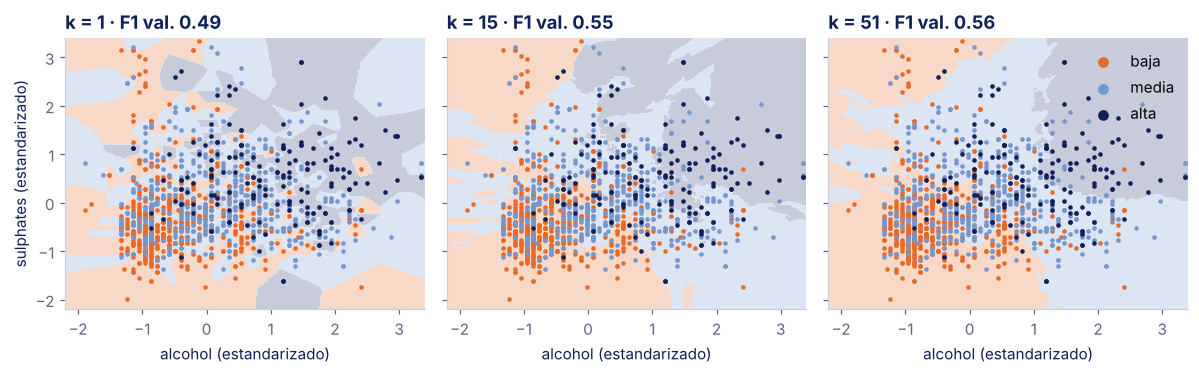

In [21]:
DOS = ["alcohol", "sulphates"]
Z = StandardScaler().fit_transform(X_e[DOS])
xx, yy = np.meshgrid(np.linspace(-2.2, 3.4, 250), np.linspace(-2.2, 3.4, 250))
fig, axs = plt.subplots(1, 3, figsize=(11, 3.5), sharey=True)
for ax, k in zip(axs, [1, 15, 51]):
    f1 = cross_val_score(KNeighborsClassifier(n_neighbors=k), Z, y_e, groups=g_e, cv=pliegues, scoring="f1_macro").mean()
    m = KNeighborsClassifier(n_neighbors=k).fit(Z, y_e)
    region = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, np.vectorize(CLASES.index)(region), levels=[-0.5, 0.5, 1.5, 2.5],
                colors=["#F8D9C8", "#DCE5F3", "#C8CCDA"])
    for c in CLASES:
        ax.scatter(*Z[y_e.to_numpy() == c].T, s=4, color=COLOR_CLASE[c], label=c)
    ax.set_xlim(-2.2, 3.4); ax.set_ylim(-2.2, 3.4)
    ax.set_title(f"k = {k} · F1 val. {f1:.2f}")
    ax.set_xlabel("alcohol (estandarizado)")
axs[0].set_ylabel("sulphates (estandarizado)")
axs[2].legend(loc="upper right", markerscale=3)
plt.tight_layout()
plt.show()

**Lectura.** Con $k = 1$, cada vino de entrenamiento crea su propia isla (F1 de 0.49); con 51 vecinos, las fronteras se suavizan (0.56).

### Elegir *k*, los pesos y la métrica

Buscamos $k$, `weights` y `p` (Manhattan o euclidiana) a la vez, con la validación agrupada:

Elegido: {'n_neighbors': 51, 'p': 1, 'weights': 'distance'} F1 macro de validación: 0.566


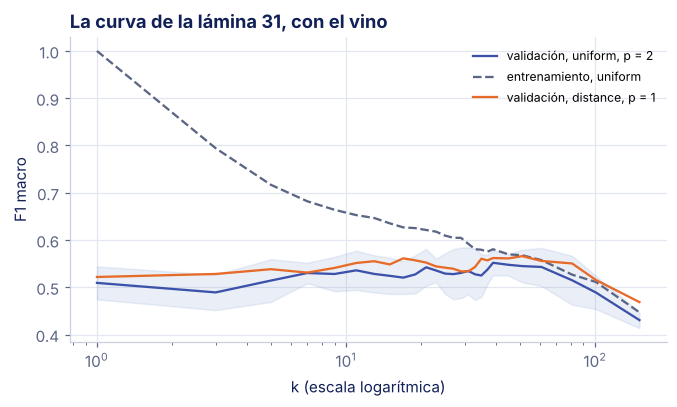

In [22]:
ks = list(range(1, 40, 2)) + [45, 51, 61, 81, 101, 151]
busqueda = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsClassifier()),
                        {"kneighborsclassifier__n_neighbors": ks, "kneighborsclassifier__weights": ["uniform", "distance"],
                         "kneighborsclassifier__p": [1, 2]},
                        cv=pliegues, scoring="f1_macro", return_train_score=True).fit(X_e, y_e, groups=g_e)
res = pd.DataFrame(busqueda.cv_results_)
print("Elegido:", {k.split("__")[1]: v for k, v in busqueda.best_params_.items()}, f"F1 macro de validación: {busqueda.best_score_:.3f}")

fig, ax = plt.subplots(figsize=(7, 3.6))
for (w, p), color, estilo in [(("uniform", 2), AZUL_MEDIO, "-"), (("distance", 1), NARANJA, "-")]:
    u = res[(res.param_kneighborsclassifier__weights == w) & (res.param_kneighborsclassifier__p == p)]
    ax.plot(ks, u.mean_test_score, color=color, linestyle=estilo, label=f"validación, {w}, p = {p}")
    if w == "uniform":
        ax.fill_between(ks, u.mean_test_score - u.std_test_score, u.mean_test_score + u.std_test_score, color=AZUL, alpha=0.15)
        ax.plot(ks, u.mean_train_score, color=GRIS, linestyle="--", label="entrenamiento, uniform")
ax.set_xscale("log"); ax.set_xlabel("k (escala logarítmica)"); ax.set_ylabel("F1 macro")
ax.set_title("La curva de la lámina 31, con el vino"); ax.legend(fontsize=8)
plt.show()

**Lectura.** En entrenamiento, $k = 1$ acierta todo: memoriza. La validación sube hasta $k \approx 10$, se mantiene entre 0.52 y 0.57 hasta $k \approx 60$ y cae después; entre pliegues varía de 0.02 a 0.05. Gana $k = 51$ con Manhattan y pesos por distancia. Con pesos por distancia, el F1 de entrenamiento vale 1 con cualquier $k$: cada vino es su propio vecino, a distancia 0.

La prueba, una sola vez, y la tabla de la unidad (notebook 14):

In [23]:
knn = busqueda.best_estimator_
modelos = {
    "kNN elegido": knn,
    "Naive Bayes": GaussianNB(),
    "regresión logística": make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=5000)),
    "árbol elegido (notebook 13)": DecisionTreeClassifier(random_state=0, max_depth=6, min_samples_leaf=5),
}
tabla_unidad = pd.DataFrame({nombre: evaluar(m) for nombre, m in modelos.items()}).T
tabla_unidad[["F1 macro, validación", "F1 macro, prueba", "aciertos", "confianza media", "log-loss"]].round(3)

,"F1 macro, validación","F1 macro, prueba",aciertos,confianza media,log-loss
kNN elegido,0.566,0.584,0.622,0.602,0.770
Naive Bayes,0.579,0.596,0.612,0.689,0.955
regresión logística,0.562,0.573,0.619,0.624,0.754
árbol elegido (notebook 13),0.584,0.551,0.581,0.759,3.133


**Lectura.** El kNN da 0.584 de F1 macro en prueba, junto a Naive Bayes (0.596), la logística (0.573) y el árbol (0.551): las diferencias no superan el ruido entre pliegues. Sus probabilidades se parecen a las de la logística (log-loss de 0.77 contra 0.75), no a las de Naive Bayes ni a las del árbol.

### Los duplicados y los pesos por distancia

El vino tiene 240 filas duplicadas. En la sesión 12, el 1 vecino bajó de 0.67 a 0.55 al poner las gemelas en el mismo pliegue. ¿Qué pasa con más vecinos y con pesos?

In [24]:
usual = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEMILLA)
juntas = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEMILLA)
duplicados = {}
for w in ["uniform", "distance"]:
    for k in [1, 5, 15, 51]:
        m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k, weights=w))
        duplicados[(w, k)] = {"partición usual": cross_val_score(m, X, y, cv=usual, scoring="f1_macro").mean(),
                              "gemelas juntas": cross_val_score(m, X, y, cv=juntas, groups=grupos, scoring="f1_macro").mean()}
duplicados = pd.DataFrame(duplicados).T
duplicados["cambio"] = duplicados["gemelas juntas"] - duplicados["partición usual"]
gemela = np.mean([np.isin(grupos.iloc[te], grupos.iloc[tr]).mean() for tr, te in usual.split(X, y)])
print(f"Vinos de prueba con su gemela en entrenamiento (partición usual): {gemela:.0%}")
duplicados.round(3)

Vinos de prueba con su gemela en entrenamiento (partición usual): 26%


partición usual  gemelas juntas  cambio
uniform  1             0.671           0.545  -0.125
         5             0.555           0.530  -0.024
         15            0.584           0.553  -0.031
         51            0.553           0.550  -0.003
distance 1             0.671           0.545  -0.125
         5             0.674           0.555  -0.119
         15            0.691           0.575  -0.116
         51            0.690           0.573  -0.117

**Lectura.** Con pesos uniformes, el efecto se diluye al crecer $k$: con 51 vecinos, la diferencia es de 0.003. Con pesos por distancia, no: la gemela está a distancia 0, recibe todo el peso y decide sola con cualquier $k$ (es la regla de Mitchell para $d = 0$). Con $k = 15$, la partición usual da 0.69, más que cualquier modelo de la unidad, y las gemelas juntas, 0.58.

### Empates en el voto

Con $k = 2$ y tres clases, los empates son frecuentes. scikit-learn se los da a la primera clase de `classes_`, que va en orden alfabético:

In [25]:
for k in [2, 3, 4]:
    m = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k)).fit(X_e, y_e)
    P = np.sort(m.predict_proba(X_p), axis=1)
    empate = P[:, -1] == P[:, -2]
    print(f"k = {k}: empata {empate.mean():.0%} de la prueba; se resuelven a favor de {pd.Series(m.predict(X_p)[empate]).value_counts().to_dict()}")

k = 2: empata 36% de la prueba; se resuelven a favor de {'baja': 71, 'alta': 45}
k = 3: empata 4% de la prueba; se resuelven a favor de {'alta': 14}
k = 4: empata 21% de la prueba; se resuelven a favor de {'baja': 44, 'alta': 24}


**Lectura.** Con $k = 2$ empata 36 % de la prueba, y ninguno se resuelve a favor de «media», la segunda clase en orden alfabético.

---

## 4. La maldición de la dimensionalidad

### Atributos irrelevantes

Agregamos al vino columnas de ruido normal, que no dicen nada de la calidad (lámina 38):

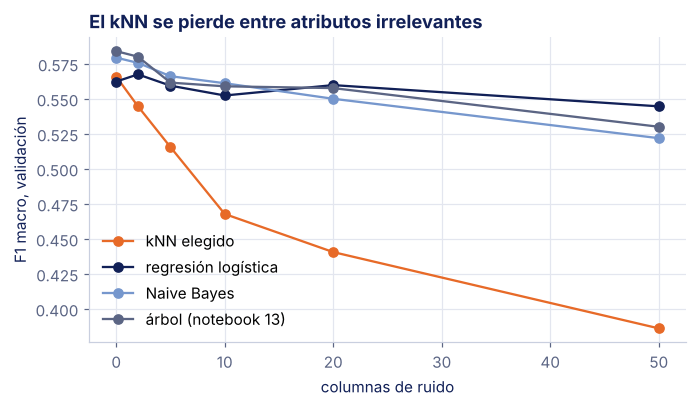

,0,2,5,10,20,50
kNN elegido,0.566,0.545,0.516,0.468,0.441,0.386
regresión logística,0.562,0.567,0.559,0.552,0.560,0.545
Naive Bayes,0.579,0.576,0.566,0.561,0.550,0.522
árbol (notebook 13),0.584,0.580,0.562,0.559,0.558,0.530


In [26]:
ruido = np.random.default_rng(SEMILLA).normal(size=(len(X), 50))
ms = [0, 2, 5, 10, 20, 50]
fabricas = {"kNN elegido": lambda: make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=51, weights="distance", p=1)),
            "regresión logística": lambda: make_pipeline(StandardScaler(), LogisticRegression(C=np.inf, max_iter=5000)),
            "Naive Bayes": lambda: GaussianNB(),
            "árbol (notebook 13)": lambda: DecisionTreeClassifier(random_state=0, max_depth=6, min_samples_leaf=5)}
curvas = {n: [] for n in fabricas}
for m in ms:
    Xr = pd.concat([X.reset_index(drop=True), pd.DataFrame(ruido[:, :m], columns=[f"ruido{i}" for i in range(m)])], axis=1)
    for n, f in fabricas.items():
        curvas[n].append(cross_val_score(f(), Xr.iloc[i_entrena], y_e, groups=g_e, cv=pliegues, scoring="f1_macro").mean())
curvas = pd.DataFrame(curvas, index=ms)
curvas.plot(figsize=(7, 3.6), color=[NARANJA, AZUL_OSCURO, AZUL, GRIS], marker="o")
plt.xlabel("columnas de ruido"); plt.ylabel("F1 macro, validación"); plt.title("El kNN se pierde entre atributos irrelevantes")
plt.show()
curvas.round(3).T

**Lectura.** Con 20 columnas de ruido, el kNN baja de 0.566 a 0.441; la logística, Naive Bayes y el árbol pierden 0.03 o menos. La distancia suma todos los atributos por igual.

El remedio de la lámina 42 es pesar los atributos; con pesos 0 o 1, es la selección de atributos de la sesión 9:

In [27]:
from sklearn.feature_selection import SequentialFeatureSelector

Xr20 = pd.concat([X.reset_index(drop=True), pd.DataFrame(ruido[:, :20], columns=[f"ruido{i}" for i in range(20)])], axis=1)
base = lambda: KNeighborsClassifier(n_neighbors=51, weights="distance", p=1)
cortes = list(pliegues.split(Xr20.iloc[i_entrena], y_e, g_e))
seleccion = make_pipeline(StandardScaler(),
                          SequentialFeatureSelector(base(), n_features_to_select="auto", tol=0.0005, scoring="f1_macro", cv=cortes),
                          base()).fit(Xr20.iloc[i_entrena], y_e)
elegidas = list(Xr20.columns[seleccion[1].get_support()])
sin_seleccion = fabricas["kNN elegido"]().fit(Xr20.iloc[i_entrena], y_e)
print("Elegidas:", elegidas)
print(f"F1 macro en prueba: {f1_score(y_p, sin_seleccion.predict(Xr20.iloc[i_prueba]), average='macro'):.3f} sin seleccionar, "
      f"{f1_score(y_p, seleccion.predict(Xr20.iloc[i_prueba]), average='macro'):.3f} con la selección")

Elegidas: ['chlorides', 'total sulfur dioxide', 'sulphates', 'alcohol']
F1 macro en prueba: 0.498 sin seleccionar, 0.545 con la selección


**Lectura.** La selección hacia adelante descarta las 20 columnas de ruido, pero también deja fuera 7 de los 11 atributos reales: la prueba sube de 0.498 a 0.545, no al 0.584 sin ruido.

### El lado del cubo y la concentración de las distancias

In [28]:
for D in [1, 2, 3, 5, 10]:
    print(f"D = {D:2d}: e(0.1) = {0.1 ** (1 / D):.2f}   e(0.01) = {0.01 ** (1 / D):.2f}")
print(f"El vino: 51 vecinos de 1279 en 11 dimensiones → {(51 / 1279) ** (1 / 11):.2f} de cada eje")

D =  1: e(0.1) = 0.10   e(0.01) = 0.01
D =  2: e(0.1) = 0.32   e(0.01) = 0.10
D =  3: e(0.1) = 0.46   e(0.01) = 0.22
D =  5: e(0.1) = 0.63   e(0.01) = 0.40
D = 10: e(0.1) = 0.79   e(0.01) = 0.63
El vino: 51 vecinos de 1279 en 11 dimensiones → 0.75 de cada eje


D =     2: más cercano / más lejano = 0.01
D =     3: más cercano / más lejano = 0.05
D =    10: más cercano / más lejano = 0.20
D =   100: más cercano / más lejano = 0.68
D =  1000: más cercano / más lejano = 0.89


D = 10000: más cercano / más lejano = 0.97


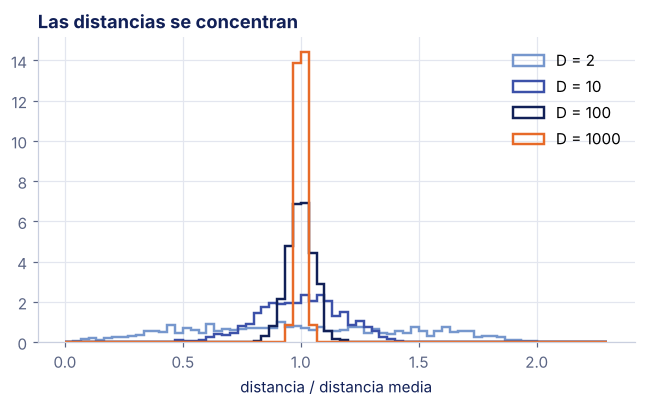

In [29]:
rng = np.random.default_rng(SEMILLA)
fig, ax = plt.subplots(figsize=(7, 3.6))
for D in [2, 3, 10, 100, 1000, 10000]:
    puntos = rng.uniform(size=(1001, D))
    d = np.sqrt(((puntos[1:] - puntos[0]) ** 2).sum(axis=1))
    print(f"D = {D:5d}: más cercano / más lejano = {d.min() / d.max():.2f}")
    if D in (2, 10, 100, 1000):
        color = {2: AZUL, 10: AZUL_MEDIO, 100: AZUL_OSCURO, 1000: NARANJA}[D]
        ax.hist(d / d.mean(), bins=np.linspace(0, 2.3, 70), density=True, histtype="step", linewidth=1.6, color=color, label=f"D = {D}")
ax.set_xlabel("distancia / distancia media"); ax.set_title("Las distancias se concentran"); ax.legend()
plt.show()

**Lectura.** Con 10 dimensiones, el cubo que contiene 10 % de los datos abarca 79 % de cada eje. Y con 1000 puntos al azar, el más cercano está a 1 % de la distancia del más lejano en 2 dimensiones, pero a 97 % en 10 000: todos quedan casi igual de lejos.

### El comportamiento en el límite (Cover y Hart)

Con $x$ uniforme y $P(y = 1 \mid x) = x$, el clasificador óptimo de Bayes falla 1/4 de las veces, y el 1 vecino con datos infinitos, 1/3 (lámina 33):

In [30]:
rng = np.random.default_rng(SEMILLA)
x_p = rng.uniform(size=(20000, 1)); y_pr = (rng.uniform(size=20000) < x_p[:, 0]).astype(int)
limite = {}
for n in [30, 100, 300, 1000, 3000, 10000, 30000]:
    kk = int(np.sqrt(n)) | 1
    e1, e2 = [], []
    for _ in range(5):
        x_e = rng.uniform(size=(n, 1)); y_en = (rng.uniform(size=n) < x_e[:, 0]).astype(int)
        e1.append(np.mean(KNeighborsClassifier(n_neighbors=1).fit(x_e, y_en).predict(x_p) != y_pr))
        e2.append(np.mean(KNeighborsClassifier(n_neighbors=kk).fit(x_e, y_en).predict(x_p) != y_pr))
    limite[n] = {"k = 1": round(float(np.mean(e1)), 3), "k ≈ √n": round(float(np.mean(e2)), 3), "k usado": kk}
pd.DataFrame(limite).T.astype({"k usado": int})

,k = 1,k ≈ √n,k usado
30,0.350,0.292,5
100,0.343,0.269,11
300,0.332,0.254,17
1000,0.335,0.254,31
3000,0.331,0.254,55
10000,0.335,0.252,101
30000,0.333,0.249,173


**Lectura.** El 1 vecino se queda en 1/3 aunque crezca $n$: a lo sumo el doble del error de Bayes. Con $k \approx \sqrt{n}$, que crece pero más despacio que $n$, se acerca a 1/4.

### El tiempo de búsqueda

Los k-d trees y ball trees aceleran la búsqueda con pocas dimensiones (lámina 43). Los tiempos dependen de la máquina:

In [31]:
rng = np.random.default_rng(SEMILLA)
tiempos = {}
for D in [2, 5, 10, 20, 50]:
    datos, consultas = rng.uniform(size=(20000, D)), rng.uniform(size=(2000, D))
    tiempos[D] = {}
    for algoritmo in ["brute", "kd_tree", "ball_tree"]:
        m = NearestNeighbors(n_neighbors=5, algorithm=algoritmo).fit(datos)
        t0 = time.perf_counter(); m.kneighbors(consultas); tiempos[D][algoritmo] = round(1000 * (time.perf_counter() - t0))
pd.DataFrame(tiempos).T.rename_axis("D").add_suffix(" (ms)")

,brute (ms),kd_tree (ms),ball_tree (ms)
D,,,
2,55,4,5
5,58,16,30
10,76,161,258
20,87,1350,901
50,81,3024,2273


**Lectura.** Con 2 dimensiones, el k-d tree es un orden de magnitud más rápido que comparar contra todos; con 10, ya es más lento. Por eso `algorithm="auto"` usa fuerza bruta si $D > 15$.

---

## 5. Vecinos para regresión

Volvemos a la diabetes de la sesión 10. `KNeighborsRegressor` promedia los valores de los $k$ vecinos; `lowess`, de `statsmodels`, ajusta en cada punto una recta ponderada por la distancia, la $E_3$ de la lámina 45.

Solo el IMC: lineal 0.306 · kNN (k = 65) 0.294 · lowess (frac = 0.7) 0.336


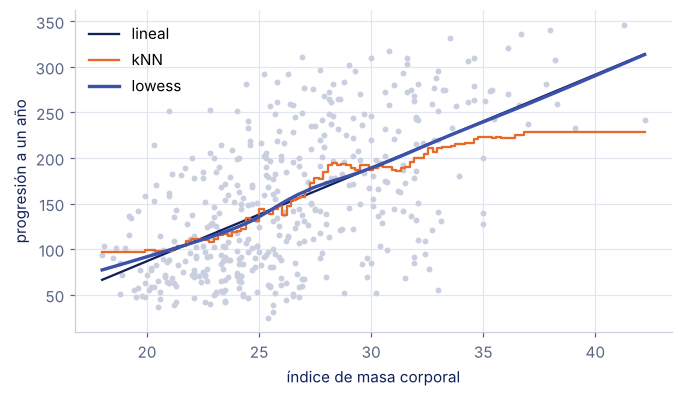

In [32]:
from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold
from sklearn.neighbors import KNeighborsRegressor
from statsmodels.nonparametric.smoothers_lowess import lowess

diabetes = load_diabetes(as_frame=True, scaled=False)
Xd, yd = diabetes.data, diabetes.target
cv = KFold(n_splits=10, shuffle=True, random_state=SEMILLA)
imc, prog = Xd["bmi"].to_numpy(float), yd.to_numpy(float)


def r2_lowess(frac):
    pred = np.empty(len(prog))
    for tr, te in cv.split(imc):
        ajuste = lowess(prog[tr], imc[tr], frac=frac, it=0)
        pred[te] = np.interp(imc[te], ajuste[:, 0], ajuste[:, 1])
    return r2_score(prog, pred)


r2_lineal = cross_val_score(LinearRegression(), Xd[["bmi"]], yd, cv=cv, scoring="r2").mean()
vec = GridSearchCV(KNeighborsRegressor(), {"n_neighbors": list(range(5, 101, 5))}, cv=cv, scoring="r2").fit(Xd[["bmi"]], yd)
r2_low, frac = max((r2_lowess(f), f) for f in [0.2, 0.3, 0.5, 0.7, 0.9])
print(f"Solo el IMC: lineal {r2_lineal:.3f} · kNN (k = {vec.best_params_['n_neighbors']}) {vec.best_score_:.3f} · lowess (frac = {frac}) {r2_low:.3f}")

malla = np.linspace(imc.min(), imc.max(), 120)
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.scatter(imc, prog, s=8, color="#C9CFDF")
ax.plot(malla, LinearRegression().fit(imc[:, None], prog).predict(malla[:, None]), color=AZUL_OSCURO, label="lineal")
ax.plot(malla, vec.best_estimator_.predict(pd.DataFrame({"bmi": malla})), color=NARANJA, drawstyle="steps-mid", label="kNN")
ax.plot(malla, np.interp(malla, *lowess(prog, imc, frac=frac, it=0).T), color=AZUL_MEDIO, linewidth=2.2, label="lowess")
ax.set_xlabel("índice de masa corporal"); ax.set_ylabel("progresión a un año"); ax.legend()
plt.show()

**Lectura.** Con un solo atributo, lowess (0.34) le gana un poco a la recta (0.31) y al kNN (0.29). $k$ y la fracción de lowess se eligieron con la misma validación, así que esos dos números son algo optimistas.

In [33]:
r2_10 = cross_val_score(LinearRegression(), Xd, yd, cv=cv, scoring="r2").mean()
vec_std = GridSearchCV(make_pipeline(StandardScaler(), KNeighborsRegressor()),
                       {"kneighborsregressor__n_neighbors": list(range(3, 61, 3)), "kneighborsregressor__weights": ["uniform", "distance"]},
                       cv=cv, scoring="r2").fit(Xd, yd)
vec_crudo = GridSearchCV(KNeighborsRegressor(), {"n_neighbors": list(range(3, 61, 3))}, cv=cv, scoring="r2").fit(Xd, yd)
print(f"Diez atributos: lineal {r2_10:.3f} · kNN estandarizado {vec_std.best_score_:.3f} · kNN sin escalar {vec_crudo.best_score_:.3f}")

Diez atributos: lineal 0.465 · kNN estandarizado 0.433 · kNN sin escalar 0.287


**Lectura.** Con los diez atributos, la regresión lineal (0.465) le gana al kNN (0.433 estandarizado, 0.287 sin escalar). Si la relación es casi lineal, el método perezoso no gana nada; es la lámina 49 con $H$ = funciones lineales: la regresión de la sesión 10 ajusta una sola recta, la local una por consulta.

---

La sesión 16 abre la última caja negra: las máquinas de soporte vectorial. Su kernel por omisión, `'rbf'`, es la gaussiana de las redes de base radial (lámina 47), y se prueba con los mismos 14 días y con el vino. La práctica de la unidad pedirá comparar los cuatro modelos con el protocolo de la sección 3.

---

### Declaración de uso de IA generativa

Este notebook fue elaborado con apoyo de Claude (Anthropic) para estructurar el contenido a partir de las diapositivas de la sesión, redactar el texto explicativo y preparar los ejemplos. El diseño pedagógico, la selección de temas y la revisión final son responsabilidad del titular del curso.

### Referencias

- Mitchell, T. M. (1997). *Machine Learning*, capítulo 8: Instance-Based Learning. McGraw-Hill.
- Cover, T., & Hart, P. (1967). Nearest neighbor pattern classification. *IEEE Transactions on Information Theory*, 13(1), 21-27.
- Hart, P. (1968). The condensed nearest neighbor rule. *IEEE Transactions on Information Theory*, 14(3), 515-516.
- Murphy, K. P. (2012). *Machine Learning: A Probabilistic Perspective*, sección 1.4.3. MIT Press.
- Cleveland, W. S. (1979). Robust locally weighted regression and smoothing scatterplots. *Journal of the American Statistical Association*, 74(368), 829-836.
- VanderPlas, J. (2022). *Python Data Science Handbook*, 2a ed. O'Reilly. [Capítulo 11: Sorting Arrays](https://jakevdp.github.io/PythonDataScienceHandbook/02.08-sorting.html), con el ejemplo de los k vecinos más cercanos.
- Cortez, P., Cerdeira, A., Almeida, F., Matos, T., & Reis, J. (2009). Modeling wine preferences by data mining from physicochemical properties. *Decision Support Systems*, 47(4), 547-553.
- Efron, B., Hastie, T., Johnstone, I., & Tibshirani, R. (2004). Least angle regression. *The Annals of Statistics*, 32(2), 407-499.
- [scikit-learn: Nearest Neighbors](https://scikit-learn.org/stable/modules/neighbors.html) · [KNeighborsClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsClassifier.html) · [statsmodels: lowess](https://www.statsmodels.org/stable/generated/statsmodels.nonparametric.smoothers_lowess.lowess.html)